 # Fusion des symptômes et de l'image

Ici ont combine les deux sources pour classer les 3 composants les plus suspects avec leurs causes probables et les vérifications à faire.

Règle de fusion:
- score des symptômes et score de l'image, chacun ramené entre 0 et 1 grace aux poids de la base de connaissances;
- score final = 60 % symptômes + 40 % images;
- L'image est peu fiable lorsque la confiance du modèle est sous 60%, dans ce cas l'image ne compte plus que pour 15 % sur la confiance.

Sections :
1. exemple de diagnostic complet;
2. évaluation sur 20 scénarios de panne, en comparant **texte seul**, **image seule** et **les deux combinés**;
3. analyse des erreurs.


In [2]:
import json
import os
import sys
from pathlib import Path

RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(RACINE)
sys.path.insert(0, str(RACINE))

import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image, ImageOps

from diagnostic.base_connaissances import BaseConnaissances
from diagnostic.fusion import MoteurFusion
from diagnostic.fusion.images import AnalyseurImage
from diagnostic.symptomes import ExtracteurSymptomes

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", None)

base = BaseConnaissances()
extracteur = ExtracteurSymptomes(base)
moteur = MoteurFusion(base, extracteur)
analyseur = AnalyseurImage(base)
print("Modules chargés")

Modules chargés


## 1. Exemple de diagnostic complet

Modifiez la description, la photo ou le composant photographié, puis réexécutez la cellule.
COMPOSANT_PHOTO peut valoir None (inconnu) ou l'un de : roulement, engrenage, arbre, courroie, joint, moteur.

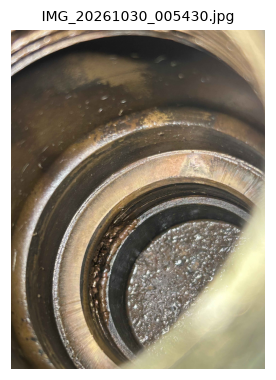

Description          : Le palier grince, chauffe beaucoup et a pris du jeu.
Symptômes détectés   : Grincement, Surchauffe, Jeu excessif
Symptômes niés       : aucun
Pièce endommagée     : 99%
Type de dommage      : Rayure / usure (défaut NEU le plus proche : Rayures, confiance 98%)
Poids utilisés       : symptômes 60%, image 40%


,Rang,Composant,Score,Score symptômes,Score image,Causes probables,Vérifications
0,1,Roulement,0.944,1.00,0.859,"Lubrification insuffisante ou dégradée ; Contamination (poussière, eau)","Vérifier l'état et le niveau du lubrifiant ; Mesurer la température du palier en fonctionnement ; Contrôler le jeu radial et axial à la main, machine arrêtée"
1,2,Engrenage,0.615,0.64,0.578,Usure des dents ; Lubrification inadéquate,"Inspecter visuellement les dents (usure, fissures, piqûres) ; Contrôler le niveau d'huile et la présence de particules métalliques ; Mesurer le jeu d'engrènement"
2,3,Arbre,0.568,0.28,1.000,Usure des portées ; Désalignement,Contrôler l'alignement (laser ou comparateur) ; Mesurer le faux-rond de l'arbre ; Faire une analyse vibratoire (composantes 1x et 2x la vitesse de rotation)


In [3]:
DESCRIPTION = "Le palier grince, chauffe beaucoup et a pris du jeu."
PHOTO = RACINE / "data" / "photos_reelles" / "plaques" / "IMG_20261030_005430.jpg"
COMPOSANT_PHOTO = None

if not PHOTO.exists():  # photo de secours : une image du jeu de test NEU
    PHOTO = sorted((RACINE / "data/images/NEU-DET/validation/images/pitted_surface").glob("*.jpg"))[0]

analyse = analyseur.analyser(PHOTO, photo_reelle="NEU-DET" not in str(PHOTO))
resultat = moteur.diagnostiquer(texte=DESCRIPTION, probas_defauts=analyse["probas_defauts"],
                                p_endommage=analyse["p_endommage"], composant_photo=COMPOSANT_PHOTO)

lib_sym = lambda ids: ", ".join(base.symptomes[s]["libelle"] for s in ids) or "aucun"
img = resultat["image"]
fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(ImageOps.exif_transpose(Image.open(PHOTO)).convert("RGB"))
ax.set_title(PHOTO.name, fontsize=9)
ax.axis("off")
plt.show()

print("Description          :", DESCRIPTION)
print("Symptômes détectés   :", lib_sym(resultat["symptomes"]))
print("Symptômes niés       :", lib_sym(resultat["symptomes_nies"]))
print(f"Pièce endommagée     : {img['p_endommage']:.0%}")
print(f"Type de dommage      : {img['type_dommage']['libelle']} (défaut NEU le plus proche : "
      f"{base.defauts[img['defaut_principal']]['libelle']}, confiance {img['confiance']:.0%})")
print(f"Poids utilisés       : symptômes {resultat['poids']['symptomes']:.0%}, image {resultat['poids']['image']:.0%}")
for a in resultat["avertissements"]:
    print("Avertissement        :", a)

pd.DataFrame([{
    "Rang": i + 1, "Composant": r["libelle"], "Score": r["score"],
    "Score symptômes": r["score_symptomes"], "Score image": r["score_image"],
    "Causes probables": " ; ".join(r["causes"]), "Vérifications": " ; ".join(r["verifications"]),
} for i, r in enumerate(resultat["classement"])])

## 2. Évaluation sur 20 scénarios de panne

Chaque scénario associe une description, une image du jeu de test NEU et le composant réellement en cause provenant du 
fichier data/scenarios_fusion.json. Pour chaque scénario, le diagnostic est calculé trois fois :
**texte seul**, **image seule** et **les deux combinés**.

Critères du plan de travail :
- le bon composant figure dans le **top 3 pour au moins 80 %** des scénarios;
- la combinaison fait **mieux que chaque source seule**.

In [4]:
scenarios = json.loads((RACINE / "data" / "scenarios_fusion.json").read_text(encoding="utf-8"))["scenarios"]
DOSSIER_NEU = RACINE / "data" / "images" / "NEU-DET" / "validation" / "images"
CONFIGS = {"Texte seul": (True, False), "Image seule": (False, True), "Texte + image": (True, True)}

lignes = []
for s in scenarios:
    images_classe = sorted((DOSSIER_NEU / s["image_neu"]["classe"]).glob("*.jpg"))
    chemin_image = images_classe[s["image_neu"]["index"] % len(images_classe)]
    analyse = analyseur.analyser(chemin_image, photo_reelle=False)
    ligne = {"#": s["id"], "Attendu": s["composant_attendu"], "Description": s["description"],
             "Image": s["image_neu"]["classe"], "Composant photo": s["composant_photo"] or "—"}
    for nom, (texte, image) in CONFIGS.items():
        r = moteur.diagnostiquer(texte=s["description"], probas_defauts=analyse["probas_defauts"],
                                 p_endommage=analyse["p_endommage"], composant_photo=s["composant_photo"],
                                 utiliser_texte=texte, utiliser_image=image)
        top = [c["id"] for c in r["classement"]]
        ligne[f"{nom} – top 3"] = " / ".join(top) or "—"
        ligne[f"{nom} – top 1 ok"] = bool(top) and top[0] == s["composant_attendu"]
        ligne[f"{nom} – top 3 ok"] = s["composant_attendu"] in top
    ligne["Symptômes détectés"] = ", ".join(r["symptomes"]) or "—"
    lignes.append(ligne)

details = pd.DataFrame(lignes)
details.to_csv(RACINE / "resultats" / "fusion_details.csv", index=False, encoding="utf-8")

synthese = pd.DataFrame({nom: {"Bon composant en 1re position": details[f"{nom} – top 1 ok"].mean(),
                               "Bon composant dans le top 3": details[f"{nom} – top 3 ok"].mean()}
                         for nom in CONFIGS}).T
top3 = synthese.loc["Texte + image", "Bon composant dans le top 3"]
meilleur = all((synthese.loc["Texte + image"] >= synthese.loc[n]).all() for n in ["Texte seul", "Image seule"])
print(f"Top 3 avec fusion : {top3:.0%}  (critère ≥ 80 %) → {'ATTEINT' if top3 >= 0.80 else 'NON ATTEINT'}")
print(f"Fusion au moins aussi bonne que chaque source seule : {'OUI' if meilleur else 'NON'}")
(RACINE / "resultats" / "fusion_synthese.json").write_text(synthese.to_json(orient="index", indent=2), encoding="utf-8")
synthese.style.format("{:.0%}")

Top 3 avec fusion : 100%  (critère ≥ 80 %) → ATTEINT
Fusion au moins aussi bonne que chaque source seule : OUI


,Bon composant en 1re position,Bon composant dans le top 3
Texte seul,70%,90%
Image seule,35%,80%
Texte + image,80%,100%


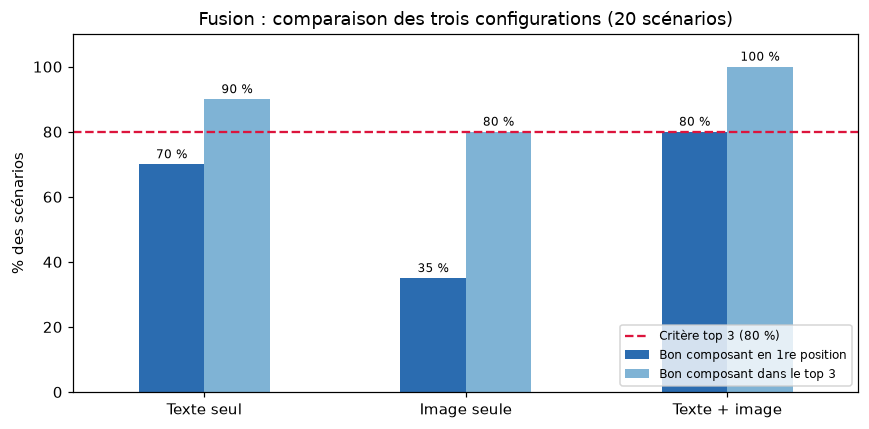

In [5]:
ax = (synthese * 100).plot.bar(figsize=(8, 4), rot=0, color=["#2b6cb0", "#7fb3d5"])
ax.axhline(80, color="crimson", linestyle="--", label="Critère top 3 (80 %)")
for conteneur in ax.containers:
    ax.bar_label(conteneur, fmt="%.0f %%", fontsize=8, padding=2)
ax.set_ylim(0, 110)
ax.set_ylabel("% des scénarios")
ax.set_title("Fusion : comparaison des trois configurations (20 scénarios)")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.savefig(RACINE / "resultats" / "fusion_comparaison.png", dpi=150)
plt.show()

In [6]:
colonnes = ["#", "Attendu", "Description", "Image", "Texte seul – top 3", "Image seule – top 3", "Texte + image – top 3"]
def colorer(ligne):
    couleurs = []
    for col in ligne.index:
        nom = col.replace(" – top 3", "")
        if col.endswith("top 3") and f"{nom} – top 1 ok" in details:
            ok1, ok3 = details.loc[ligne.name, f"{nom} – top 1 ok"], details.loc[ligne.name, f"{nom} – top 3 ok"]
            couleurs.append("background-color: #d3f9d8; color: black" if ok1 else
                            "background-color: #fff3bf; color: black" if ok3 else "background-color: #ffe3e3; color: black")
        else:
            couleurs.append("")
    return couleurs

details[colonnes].style.apply(colorer, axis=1).hide(axis="index")

#,Attendu,Description,Image,Texte seul – top 3,Image seule – top 3,Texte + image – top 3
1,roulement,Le palier grince et devient très chaud après une heure de marche.,pitted_surface,roulement / moteur / engrenage,roulement / engrenage / arbre,roulement / engrenage / moteur
2,roulement,Ça vibre et on entend un bruit régulier à chaque tour.,pitted_surface,engrenage / roulement / arbre,roulement / engrenage / arbre,roulement / engrenage / arbre
3,roulement,L'arbre a pris du jeu et ça couine au démarrage.,patches,roulement / engrenage / arbre,arbre / engrenage / roulement,roulement / engrenage / arbre
4,roulement,"Ça grince, mais aucune fuite.",patches,roulement / engrenage / courroie,arbre / engrenage / roulement,roulement / engrenage / arbre
5,roulement,Le roulement fait un drôle de bruit.,pitted_surface,—,roulement,roulement
6,engrenage,Le réducteur claque à chaque rotation.,crazing,engrenage / arbre / roulement,arbre / engrenage / roulement,engrenage / arbre / roulement
7,engrenage,On entend des chocs dans la boîte et le carter chauffe.,crazing,engrenage / roulement / moteur,arbre / engrenage / roulement,engrenage / roulement / arbre
8,engrenage,La transmission fait un cliquetis et se bloque parfois.,inclusion,engrenage / roulement / arbre,arbre / engrenage / roulement,engrenage / roulement / arbre
9,engrenage,Ça fait un bruit bizarre depuis ce matin.,crazing,—,arbre / engrenage / roulement,arbre / engrenage / roulement
10,arbre,Grosses vibrations quand la vitesse augmente et le moteur consomme beaucoup plus.,crazing,moteur / roulement / arbre,arbre / engrenage / roulement,arbre / roulement / engrenage


,Bon composant en 1re position,Bon composant dans le top 3
Image choisie pour le scénario,80%,100%
N'importe quelle image (moyenne des 6),66%,98%


Mesure si la réponse est juste ou pas.  Vert : Est la première solution proposée. Jaune : dans le top 3. Rouge : absent du top 3.

## 3. Scénarios où la fusion se trompe de premier composant

In [7]:
erreurs = details[~details["Texte + image – top 1 ok"]]
print(f"{len(erreurs)} scénario(s) sur {len(details)}")
erreurs[["#", "Attendu", "Description", "Symptômes détectés", "Image", "Texte + image – top 3"]]

4 scénario(s) sur 20


,#,Attendu,Description,Symptômes détectés,Image,Texte + image – top 3
8,9,engrenage,Ça fait un bruit bizarre depuis ce matin.,—,crazing,arbre / engrenage / roulement
10,11,arbre,On entend un bruit cyclique et un claquement au démarrage.,"bruit_cyclique, claquement",rolled-in_scale,engrenage / arbre / roulement
14,15,courroie,Sifflement aigu et la poulie vibre.,"sifflement, vibration",crazing,roulement / arbre / courroie
18,19,moteur,Le moteur chauffe et le disjoncteur saute.,"surchauffe, conso_elevee",patches,roulement / engrenage / moteur
